# 03. 위그너 분포
목표: 같은 처프를 스펙트로그램과 위그너 분포로 비교하고, 위그너 분포의 장점(선명함)과 단점(교차항)을 확인한다.

In [ ]:
# 위그너 분포 함수
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import chirp, hilbert

fs = 1000
t = np.arange(0, 2, 1/fs)
x = chirp(t, f0=5, t1=2, f1=100, method='linear')

def wigner_ville(x, fs, nfft=512):
    z = hilbert(x)
    N = len(z)
    W = np.zeros((nfft, N))
    for n in range(N):
        m_max = min(n, N-1-n, nfft//2-1)
        m = np.arange(-m_max, m_max+1)
        r = np.zeros(nfft, dtype=complex)
        r[m%nfft] = z[n+m] * np.conj(z[n-m])
        W[:, n] = np.real(np.fft.fft(r))
    freqs = np.arange(nfft) * fs / (2 * nfft)
    return W, freqs

## 실험 1 예상
- 위그너 분포의 선이 스펙트로그램보다 얇을 것이다. 위그너 분포는 시각 n일 때 앞으로 m칸 뒤로 m칸에 위치한 분포를 서로 곱하기 때문에 변화가 상쇄되어 chirp가 linear일 때는 이론상 선에 모두 모일 것이다.
- 단, 그림의 양 끝(0초, 2초)에서는 선이 번질 것이다. 양 끝에서는 앞이나 뒤로 밀 수 있는 거리가 작아서 정보가 적다. (보는 범위가 짧으면 주파수 구분이 흐려짐)

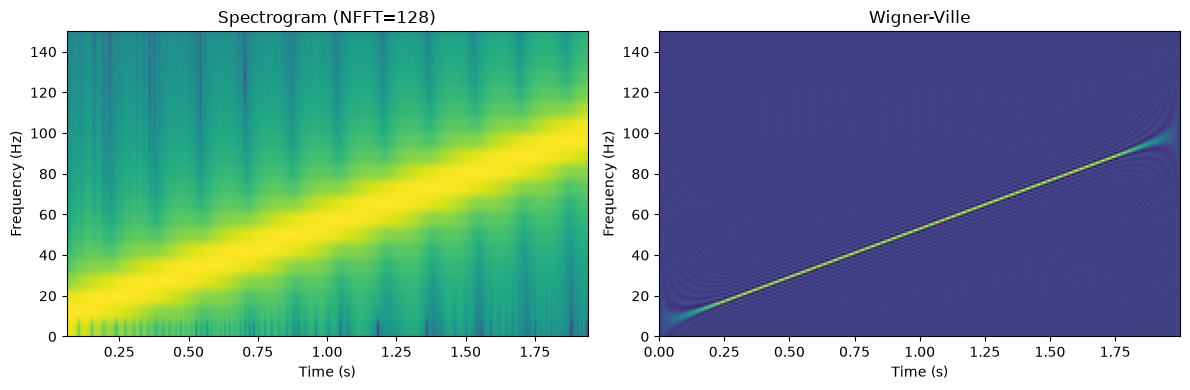

In [6]:
W, freqs = wigner_ville(x, fs)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].specgram(x, NFFT=128, Fs=fs, noverlap=120)
ax[0].set_title("Spectrogram (NFFT=128)")
ax[1].imshow(W, aspect='auto', origin='lower',
             extent=[t[0], t[-1], 0, fs/2])
ax[1].set_title("Wigner-Ville")
for a in ax:
    a.set_xlabel("Time (s)")
    a.set_ylabel("Frequency (Hz)")
    a.set_ylim(0, 150)
plt.tight_layout()
plt.show()

## 실험 1 관찰
- 예상 1 (선이 얇다): 맞음. 위그너 분포에서 처프가 대각산 위에 가늘게 모였다. 스펙트로그램보다 확실히 얇다.
- 예상 2 (양 끝이 번진다): 맞음. 0초, 2초 근처에서 선이 번졌다.

## 실험 2 예상
- 두 처프의 중간 주파수는 0초, 1초, 2초 모두 52.5Hz이다. (하나가 올라간 만큼 다른 하나가 내려가므로 항상 일정)
- 따라서 위그너 분포에는 X자 외에 52.5Hz 높이의 가짜 수평선(교차항)이 생길 것이다.
- 스펙트로그램에는 이 수평선이 없을 것이다.

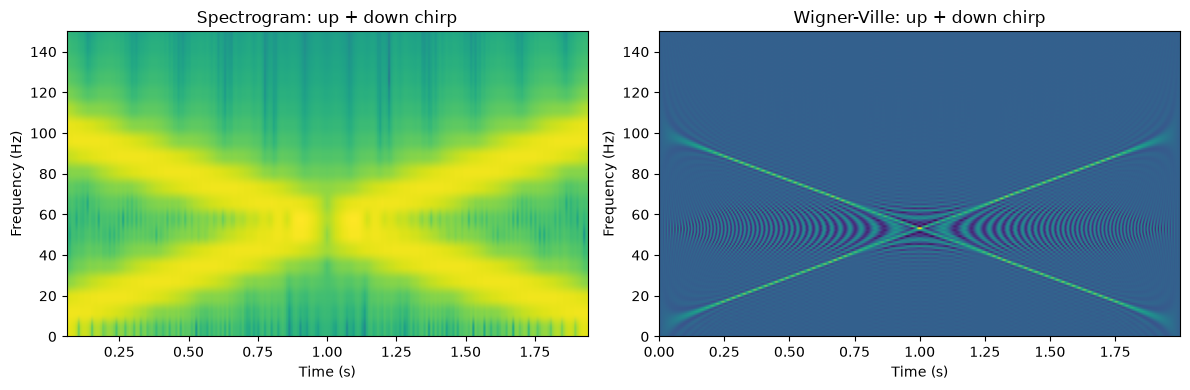

In [8]:
x2 = x + chirp(t, f0=100, t1=2, f1=5, method='linear')
W2, freqs = wigner_ville(x2, fs)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].specgram(x2, NFFT=128, Fs=fs, noverlap=120)
ax[0].set_title("Spectrogram: up + down chirp")
ax[1].imshow(W2, aspect='auto', origin='lower',
             extent=[t[0], t[-1], 0, fs/2])
ax[1].set_title("Wigner-Ville: up + down chirp")
for a in ax:
    a.set_xlabel("Time (s)")
    a.set_ylabel("Frequency (Hz)")
    a.set_ylim(0, 150)
plt.tight_layout()
plt.show()

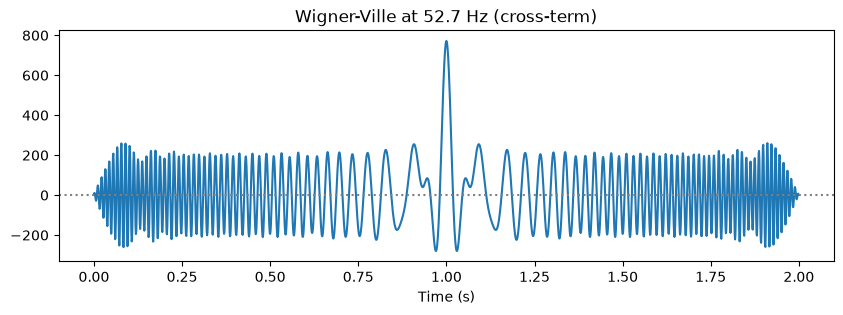

In [10]:
idx = np.argmin(np.abs(freqs - 52.5))   # 52.5Hz에 가장 가까운 행 번호 찾기

plt.figure(figsize=(10, 3))
plt.plot(t, W2[idx])
plt.axhline(0, color="gray", linestyle=":")
plt.title(f"Wigner-Ville at {freqs[idx]:.1f} Hz (cross-term)")
plt.xlabel("Time (s)")
plt.show()

## 실험 2 관찰
- 예상 1 (52.5Hz에 가짜 선): 맞음. X자 외에 52.5Hz 근처에 무늬가 생겼다
- 예상 2 (스펙트로그램에는 없음): 맞음. 스펙트로그램에는 X자만 보였다.
- 매끈한 선이 아닌 줄무늬가 보인다. 선이라기보다 번지는 물결 모양이다.

## 실험 2 해석
- 위그너 분포는 신호를 자기 자신과 곱한다. 두 처프가 섞인 신호를 곱하면 (a+b)*(a+b)처럼 엇갈린 곱 a * b가 생긴다.
- 엇갈린 곱은 두 주파수의 평균 위치(항상 52.5Hz)에 나타난다. -> 교차항
- 두 처프의 엇갈림(위상 차이)이 시간에 따라 변해서 값이 양수/음수를 오가므로 물결 모양이 된다.
- 스펙트로그램은 신호끼리 곱하지 않으므로 교차항이 없다.

## 03 결론
- 위그너 분포: 처프 하나는 스펙트로그램보다 훨씬 가늘게 그려진다 (실험 1). 하지만 신호가 여러 개라면 가짜 무늬가 생긴다 (실험 2)
- 장점(가는 선)과 단점(교차항)이 모두 "자기 자신과 곱한다"는 같은 원인에서 나온다
- 스펙트로그램과 위그너 분포는 각각 장단점이 있고, 상황에 맞게 골라야 한다.

True


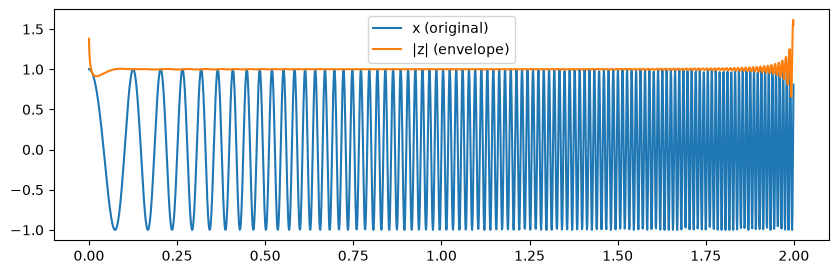

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import chirp, hilbert

fs = 1000
t = np.arange(0, 2, 1/fs)
x = chirp(t, f0=5, t1=2, f1=100, method='linear')

z = hilbert(x)
print(np.allclose(np.real(z), x))   # 실수 부분이 원래 신호와 같은가?

plt.figure(figsize=(10, 3))
plt.plot(t, x, label="x (original)")
plt.plot(t, np.abs(z), label="|z| (envelope)")
plt.legend()
plt.show()

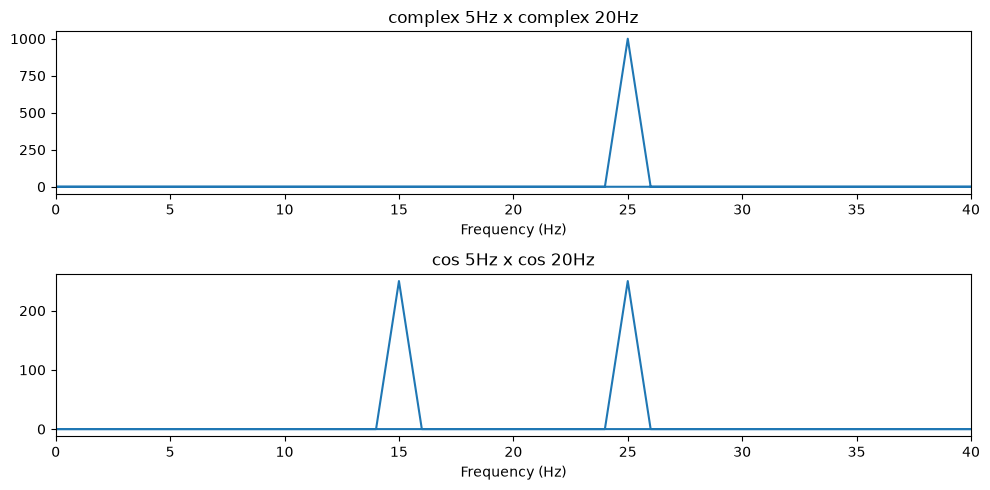

In [9]:
t1 = np.arange(0, 1, 1/fs)
f = np.fft.fftfreq(len(t1), 1/fs)

# 복소 파동끼리 곱하기
a = np.exp(1j*2*np.pi*5*t1)
b = np.exp(1j*2*np.pi*20*t1)
prod_complex = np.abs(np.fft.fft(a * b))

# 실수 코사인끼리 곱하기
c = np.cos(2*np.pi*5*t1) * np.cos(2*np.pi*20*t1)
prod_real = np.abs(np.fft.fft(c))

fig, ax = plt.subplots(2, 1, figsize=(10, 5))
ax[0].plot(f, prod_complex)
ax[0].set_title("complex 5Hz x complex 20Hz")
ax[1].plot(f, prod_real)
ax[1].set_title("cos 5Hz x cos 20Hz")
for a_ in ax:
    a_.set_xlim(0, 40)
    a_.set_xlabel("Frequency (Hz)")
plt.tight_layout()
plt.show()